# Quantile Regression Forest (Meinshausen 2006)

Random forest fit on lag-window features; intervals come from weighted quantiles of training labels in the leaves the test point lands in (Meinshausen 2006).  See `src/analysis/Simple_Native/README.md`.

**Workflow.** This notebook (i) runs `tree_based` on every `(ticker, regime)` cell — *idempotently*, skipping cells whose CSV already exists in `results/`; (ii) loads those CSVs and writes a per-cell timeline figure into `report/figures/timelines/Simple_Native/`; (iii) prints a per-cell metrics table and a summary.

In [1]:
# sys.path bootstrap so 'from src...' works regardless of CWD
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "requirements.txt").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project root:", ROOT)


project root: \\wsl.localhost\Ubuntu\home\jsarin\conformalQuant


In [2]:
import warnings, glob, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.analysis._shared import (
    RESULTS_DIR, CRISIS_WINDOWS, MODEL_CATEGORIES,
    ensure_data, iterate_experiments, walk_forward, save_intervals, make_wrapper,
)
from src.plotting import plot_interval_timeline, compute_cell_metrics, render_cell_grid

FORCE_RERUN = False  # set True to ignore cached CSVs and re-run every cell


## 1. Run `tree_based` (idempotent — set `FORCE_RERUN = True` to override)

In [3]:
from src.conformal.tree_native import QuantileTreeNative
data = ensure_data()
print(f"data: {len(data):,} rows  |  {data.index.min().date()} -> {data.index.max().date()}")

MODEL_NAME = "tree_based"
WRAPPERS = ["native"]
print(f"\nRunning {MODEL_NAME} on every (ticker, regime) cell ...")

for split in iterate_experiments():
    out = RESULTS_DIR / f"{MODEL_NAME}_native_{split.ticker.value}_{split.regime}.csv"
    if out.exists() and not FORCE_RERUN:
        print(f"  cached  {split.regime} {split.ticker.value}")
        continue
    train = split.slice_train(data); calib = split.slice_calib(data); full = split.slice_full(data)
    if len(train) < 60:
        print(f"  skip {split.regime} {split.ticker.value} — only {len(train)} train rows")
        continue
    t0 = time.perf_counter()
    try:
        m = QuantileTreeNative(label_col_name=split.label_col, num_lags=5, confidence_level=0.90)
        m.fit_and_calibrate(train, calib)
        intervals = walk_forward(m, full, split.test_start, split.test_end)
        save_intervals(intervals, MODEL_NAME, "native", split.ticker, split.regime)
        cell = compute_cell_metrics(intervals)
        print(f"  {split.regime} {split.ticker.value:5s}: "
              f"cov={cell['cov']:.3f}  W={cell['winkler']:.3f}  width={cell['width']:.4f}  "
              f"({time.perf_counter()-t0:.1f}s)")
    except Exception as e:
        print(f"  {split.regime} {split.ticker.value:5s}: SKIPPED ({type(e).__name__}: {e})")
        if out.exists(): out.unlink()


data: 5,863 rows  |  2003-01-03 -> 2026-04-23

Running tree_based on every (ticker, regime) cell ...
  cached  2008 AIG
  cached  2008 GNW
  cached  2008 MGM
  cached  2020 MCD
  cached  2020 MGM
  cached  2020 AZO
  cached  2022 SNAP
  cached  2022 NFLX
  cached  2022 META


## 2. Render timeline figures, one per cell

In [4]:
CATEGORY = "Simple_Native"
MODEL_NAME = "tree_based"
import pathlib
out_dir = ROOT / "report" / "figures" / "timelines" / CATEGORY
patterns = [str(RESULTS_DIR / f"{MODEL_NAME}_*_*.csv")]
files = sorted({f for p in patterns for f in glob.glob(p)})
files = [f for f in files if pathlib.Path(f).name.startswith(f"{MODEL_NAME}_")]
if not files:
    raise RuntimeError(f"no CSVs for model={MODEL_NAME!r}; did the run cell finish?")
raw = pd.concat([pd.read_csv(f, parse_dates=["date"]) for f in files], ignore_index=True)
raw = raw[raw["model"] == MODEL_NAME]
metrics = render_cell_grid(
    raw, model_filter=[MODEL_NAME], out_dir=out_dir,
    crisis_windows=CRISIS_WINDOWS, category_lookup=MODEL_CATEGORIES,
)
print(f"wrote {len(metrics)} timeline figures → {out_dir.relative_to(ROOT)}")
metrics_sorted = metrics.sort_values(["wrapper", "regime", "ticker"]).reset_index(drop=True)
display(metrics_sorted.round(3))


wrote 9 timeline figures → report\figures\timelines\Simple_Native


,model,wrapper,ticker,regime,cov,winkler,width,n
0,tree_based,native,AIG,2008,0.467,0.877,0.085,390
1,tree_based,native,GNW,2008,0.459,0.948,0.071,390
2,tree_based,native,MGM,2008,0.459,0.676,0.071,390
3,tree_based,native,AZO,2020,0.826,0.122,0.042,304
4,tree_based,native,MCD,2020,0.812,0.119,0.033,304
5,tree_based,native,MGM,2020,0.737,0.300,0.071,304
6,tree_based,native,META,2022,0.820,0.161,0.069,501
7,tree_based,native,NFLX,2022,0.858,0.157,0.082,501
8,tree_based,native,SNAP,2022,0.820,0.270,0.113,501


## 3. Summary aggregated across (ticker, regime)


tree_based — average across all 9 (ticker, regime) cells (lower Winkler = better)


,cov,winkler,width
wrapper,,,
native,0.695,0.403,0.071



Representative figure (tree_based_native_AIG_2008.png):


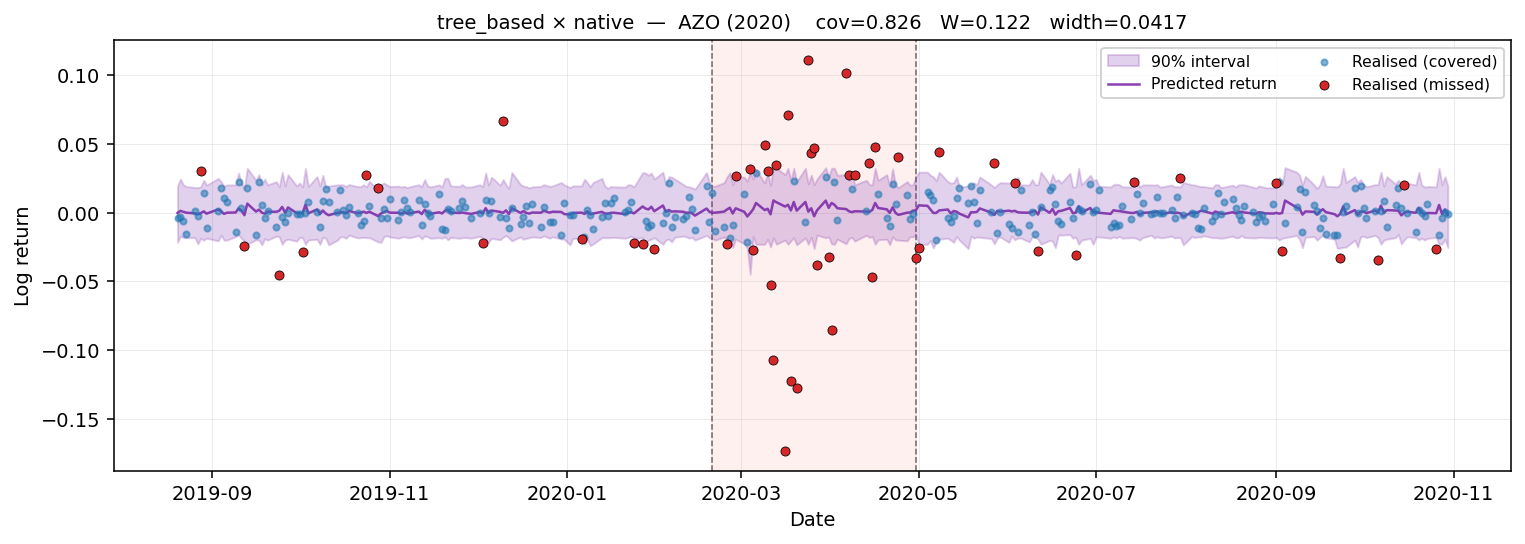

In [6]:
# Aggregate by wrapper — mean across all (ticker, regime) cells
summary = (
    metrics_sorted
    .groupby("wrapper")[["cov", "winkler", "width"]]
    .mean()
    .sort_values("winkler")
    .round(3)
)
print(f"\n{MODEL_NAME} — average across all 9 (ticker, regime) cells (lower Winkler = better)")
display(summary)

# Show one representative figure inline
sample = sorted((ROOT / "report" / "figures" / "timelines" / CATEGORY).glob(f"{MODEL_NAME}_*.png"))
if sample:
    print(f"\nRepresentative figure ({sample[0].name}):")
    display(Image(filename=str(sample[1])))
